<a href="https://colab.research.google.com/github/ssunny6453-ui/python.py/blob/main/Virtual_Memory_Locality_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("Virtual-Memory Locality Analyzer")
print("Student Name: VASALLI SWAPNITH")
print("USN: 25BTRPW100")

Virtual-Memory Locality Analyzer
Student Name: VASALLI SWAPNITH
USN: 25BTRPW100


In [2]:
NUM_PAGES = 20
NUM_FRAMES = 4
NUM_REFERENCES = 100
WINDOW_SIZE = 10

print("Virtual Pages:", NUM_PAGES)
print("Physical Frames:", NUM_FRAMES)
print("Memory References:", NUM_REFERENCES)
print("Working-Set Window:", WINDOW_SIZE)

Virtual Pages: 20
Physical Frames: 4
Memory References: 100
Working-Set Window: 10


In [4]:
import random

def generate_strong_locality(num_references, locality_pages):
    pattern = []

    for _ in range(num_references):
        page = random.choice(locality_pages)
        pattern.append(page)

    return pattern

strong_locality_pages = [2, 3, 4, 5]

strong_pattern = generate_strong_locality(
    NUM_REFERENCES,
    strong_locality_pages
)

print("Strong Locality Pattern:")
print(strong_pattern)

Strong Locality Pattern:
[4, 3, 5, 5, 5, 2, 3, 2, 4, 3, 3, 3, 3, 4, 2, 3, 2, 5, 5, 3, 4, 3, 2, 5, 2, 5, 2, 2, 3, 5, 3, 4, 3, 3, 5, 2, 2, 4, 5, 3, 2, 5, 4, 4, 5, 4, 5, 4, 2, 2, 2, 2, 3, 5, 4, 5, 3, 2, 3, 3, 2, 4, 5, 3, 2, 2, 4, 5, 2, 4, 3, 3, 2, 2, 4, 4, 2, 2, 3, 3, 4, 3, 5, 5, 4, 4, 5, 3, 4, 4, 3, 5, 3, 4, 3, 3, 3, 5, 5, 5]


In [5]:
def generate_weak_locality(num_references, num_pages):
    pattern = []

    for _ in range(num_references):
        page = random.randint(1, num_pages)
        pattern.append(page)

    return pattern

weak_pattern = generate_weak_locality(
    NUM_REFERENCES,
    NUM_PAGES
)

print("Weak Locality Pattern:")
print(weak_pattern)

Weak Locality Pattern:
[15, 18, 2, 7, 15, 18, 2, 12, 17, 9, 18, 12, 16, 5, 2, 12, 20, 16, 20, 3, 17, 11, 2, 11, 16, 17, 9, 9, 1, 9, 1, 17, 6, 13, 17, 14, 19, 2, 16, 3, 16, 13, 15, 18, 7, 15, 13, 2, 17, 2, 7, 11, 10, 1, 5, 8, 4, 14, 16, 19, 11, 2, 17, 11, 2, 9, 19, 12, 19, 2, 11, 7, 6, 4, 18, 19, 20, 6, 17, 13, 7, 7, 17, 7, 7, 7, 11, 17, 8, 4, 10, 18, 20, 16, 7, 17, 11, 11, 1, 19]


In [6]:
import random
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
def fifo_page_replacement(reference_string, num_frames):
    frames = []
    page_faults = 0
    page_hits = 0

    for page in reference_string:

        if page in frames:
            page_hits += 1

        else:
            page_faults += 1

            if len(frames) < num_frames:
                frames.append(page)

            else:
                frames.pop(0)
                frames.append(page)

    return page_faults, page_hits

In [9]:
# This cell caused a SyntaxError because 'return' was used outside of a function.
# The FIFO page replacement function was already fully defined in the previous cell.

In [10]:
strong_fifo_faults, strong_fifo_hits = fifo_page_replacement(
    strong_pattern,
    NUM_FRAMES
)

weak_fifo_faults, weak_fifo_hits = fifo_page_replacement(
    weak_pattern,
    NUM_FRAMES
)

print("FIFO - Strong Locality")
print("Page Faults:", strong_fifo_faults)
print("Page Hits:", strong_fifo_hits)

print()

print("FIFO - Weak Locality")
print("Page Faults:", weak_fifo_faults)
print("Page Hits:", weak_fifo_hits)

FIFO - Strong Locality
Page Faults: 4
Page Hits: 96

FIFO - Weak Locality
Page Faults: 74
Page Hits: 26


In [11]:
def lru_page_replacement(reference_string, num_frames):
    frames = []
    page_faults = 0
    page_hits = 0

    for page in reference_string:

        if page in frames:
            page_hits += 1
            frames.remove(page)
            frames.append(page)

        else:
            page_faults += 1

            if len(frames) < num_frames:
                frames.append(page)

            else:
                frames.pop(0)
                frames.append(page)

    return page_faults, page_hits

In [12]:
strong_lru_faults, strong_lru_hits = lru_page_replacement(
    strong_pattern,
    NUM_FRAMES
)

weak_lru_faults, weak_lru_hits = lru_page_replacement(
    weak_pattern,
    NUM_FRAMES
)

print("LRU - Strong Locality")
print("Page Faults:", strong_lru_faults)
print("Page Hits:", strong_lru_hits)

print()

print("LRU - Weak Locality")
print("Page Faults:", weak_lru_faults)
print("Page Hits:", weak_lru_hits)

LRU - Strong Locality
Page Faults: 4
Page Hits: 96

LRU - Weak Locality
Page Faults: 72
Page Hits: 28


In [13]:
def optimal_page_replacement(reference_string, num_frames):
    frames = []
    page_faults = 0
    page_hits = 0

    for i in range(len(reference_string)):
        page = reference_string[i]

        if page in frames:
            page_hits += 1

        else:
            page_faults += 1

            if len(frames) < num_frames:
                frames.append(page)

            else:
                future_pages = reference_string[i + 1:]
                farthest = -1
                page_to_replace = None

                for frame_page in frames:

                    if frame_page not in future_pages:
                        page_to_replace = frame_page
                        break

                    next_use = future_pages.index(frame_page)

                    if next_use > farthest:
                        farthest = next_use
                        page_to_replace = frame_page

                frames.remove(page_to_replace)
                frames.append(page)

    return page_faults, page_hits

In [14]:
strong_optimal_faults, strong_optimal_hits = optimal_page_replacement(
    strong_pattern,
    NUM_FRAMES
)

weak_optimal_faults, weak_optimal_hits = optimal_page_replacement(
    weak_pattern,
    NUM_FRAMES
)

print("Optimal - Strong Locality")
print("Page Faults:", strong_optimal_faults)
print("Page Hits:", strong_optimal_hits)

print()

print("Optimal - Weak Locality")
print("Page Faults:", weak_optimal_faults)
print("Page Hits:", weak_optimal_hits)

Optimal - Strong Locality
Page Faults: 4
Page Hits: 96

Optimal - Weak Locality
Page Faults: 52
Page Hits: 48


In [15]:
print("PAGE FAULT RATES")
print()

print("FIFO:")
print("Strong Locality:", strong_fifo_faults / NUM_REFERENCES * 100, "%")
print("Weak Locality:", weak_fifo_faults / NUM_REFERENCES * 100, "%")

print()

print("LRU:")
print("Strong Locality:", strong_lru_faults / NUM_REFERENCES * 100, "%")
print("Weak Locality:", weak_lru_faults / NUM_REFERENCES * 100, "%")

print()

print("Optimal:")
print("Strong Locality:", strong_optimal_faults / NUM_REFERENCES * 100, "%")
print("Weak Locality:", weak_optimal_faults / NUM_REFERENCES * 100, "%")

PAGE FAULT RATES

FIFO:
Strong Locality: 4.0 %
Weak Locality: 74.0 %

LRU:
Strong Locality: 4.0 %
Weak Locality: 72.0 %

Optimal:
Strong Locality: 4.0 %
Weak Locality: 52.0 %


In [16]:
def calculate_working_set(reference_string, window_size):
    working_set_sizes = []

    for i in range(len(reference_string)):
        start = max(0, i - window_size + 1)
        window = reference_string[start:i + 1]

        unique_pages = set(window)
        working_set_sizes.append(len(unique_pages))

    return working_set_sizes


strong_working_set = calculate_working_set(
    strong_pattern,
    WINDOW_SIZE
)

weak_working_set = calculate_working_set(
    weak_pattern,
    WINDOW_SIZE
)

print("Strong Locality Working Set")
print(strong_working_set)

print()

print("Weak Locality Working Set")
print(weak_working_set)

Strong Locality Working Set
[1, 2, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]

Weak Locality Working Set
[1, 2, 3, 4, 4, 4, 4, 5, 6, 7, 7, 7, 8, 8, 7, 7, 8, 8, 7, 7, 7, 8, 8, 7, 7, 6, 7, 7, 7, 6, 6, 6, 6, 6, 5, 6, 7, 8, 9, 9, 8, 8, 8, 9, 9, 8, 7, 7, 8, 7, 6, 7, 8, 8, 9, 9, 9, 10, 10, 10, 9, 10, 10, 9, 8, 8, 7, 7, 6, 6, 6, 7, 7, 8, 9, 8, 9, 8, 9, 9, 8, 8, 8, 7, 6, 5, 5, 4, 5, 5, 6, 7, 8, 9, 9, 9, 9, 9, 9, 9]


In [17]:
strong_average = sum(strong_working_set) / len(strong_working_set)
strong_maximum = max(strong_working_set)

weak_average = sum(weak_working_set) / len(weak_working_set)
weak_maximum = max(weak_working_set)

print("WORKING-SET ANALYSIS")
print()

print("Strong Locality")
print("Average Working Set:", round(strong_average, 2))
print("Maximum Working Set:", strong_maximum)

print()

print("Weak Locality")
print("Average Working Set:", round(weak_average, 2))
print("Maximum Working Set:", weak_maximum)

WORKING-SET ANALYSIS

Strong Locality
Average Working Set: 3.67
Maximum Working Set: 4

Weak Locality
Average Working Set: 7.22
Maximum Working Set: 10


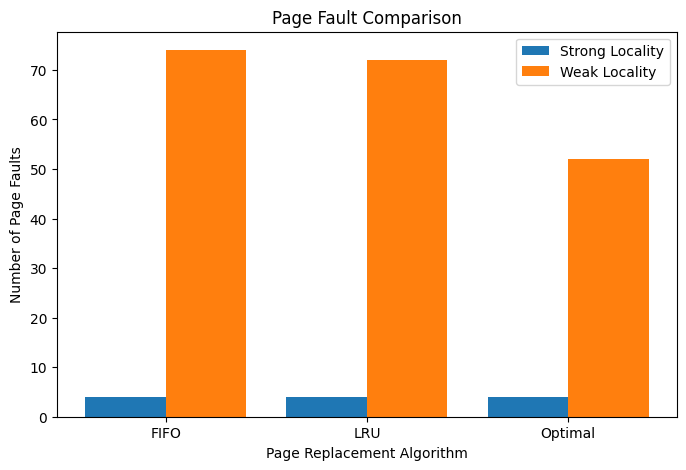

In [18]:
algorithms = ["FIFO", "LRU", "Optimal"]

strong_faults = [
    strong_fifo_faults,
    strong_lru_faults,
    strong_optimal_faults
]

weak_faults = [
    weak_fifo_faults,
    weak_lru_faults,
    weak_optimal_faults
]

x = range(len(algorithms))

plt.figure(figsize=(8, 5))

plt.bar(
    [i - 0.2 for i in x],
    strong_faults,
    width=0.4,
    label="Strong Locality"
)

plt.bar(
    [i + 0.2 for i in x],
    weak_faults,
    width=0.4,
    label="Weak Locality"
)

plt.xticks(list(x), algorithms)
plt.xlabel("Page Replacement Algorithm")
plt.ylabel("Number of Page Faults")
plt.title("Page Fault Comparison")
plt.legend()

plt.show()

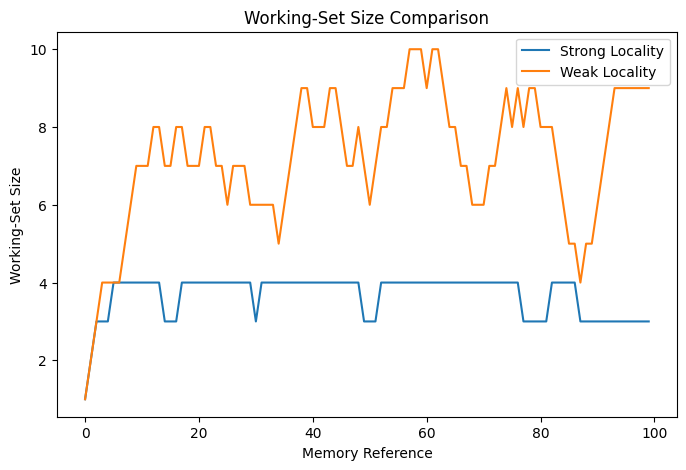

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    strong_working_set,
    label="Strong Locality"
)

plt.plot(
    weak_working_set,
    label="Weak Locality"
)

plt.xlabel("Memory Reference")
plt.ylabel("Working-Set Size")
plt.title("Working-Set Size Comparison")
plt.legend()

plt.show()

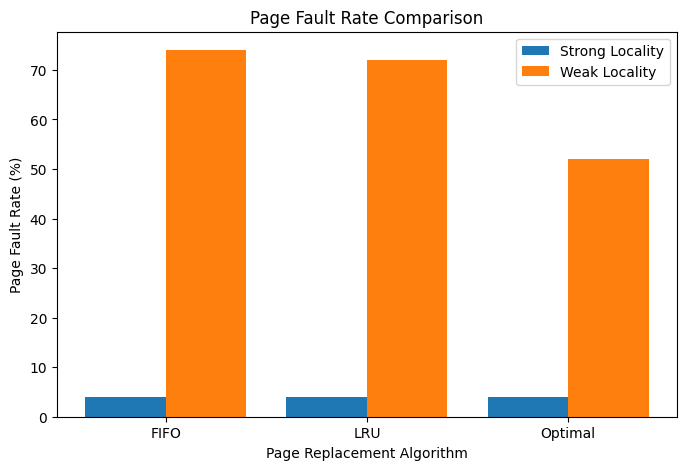

In [20]:
strong_fault_rates = [
    strong_fifo_faults / NUM_REFERENCES * 100,
    strong_lru_faults / NUM_REFERENCES * 100,
    strong_optimal_faults / NUM_REFERENCES * 100
]

weak_fault_rates = [
    weak_fifo_faults / NUM_REFERENCES * 100,
    weak_lru_faults / NUM_REFERENCES * 100,
    weak_optimal_faults / NUM_REFERENCES * 100
]

plt.figure(figsize=(8, 5))

plt.bar(
    [i - 0.2 for i in range(3)],
    strong_fault_rates,
    width=0.4,
    label="Strong Locality"
)

plt.bar(
    [i + 0.2 for i in range(3)],
    weak_fault_rates,
    width=0.4,
    label="Weak Locality"
)

plt.xticks(range(3), ["FIFO", "LRU", "Optimal"])
plt.xlabel("Page Replacement Algorithm")
plt.ylabel("Page Fault Rate (%)")
plt.title("Page Fault Rate Comparison")
plt.legend()

plt.show()

In [22]:
# Define moderate_reference_string if it doesn't already exist
if 'moderate_reference_string' not in globals():
    # Simulating a moderate locality pattern (combining localized segments with occasional random jumps)
    moderate_reference_string = [random.choice([1, 2, 3, 4, 5]) if i % 10 < 7 else random.randint(1, 20) for i in range(100)]

# Correcting the function names to match their definitions
moderate_fifo_faults, _ = fifo_page_replacement(moderate_reference_string, 4)
moderate_lru_faults, _ = lru_page_replacement(moderate_reference_string, 4)
moderate_optimal_faults, _ = optimal_page_replacement(moderate_reference_string, 4)

print("Moderate Locality Results")
print("FIFO Faults:", moderate_fifo_faults)
print("LRU Faults:", moderate_lru_faults)
print("Optimal Faults:", moderate_optimal_faults)

Moderate Locality Results
FIFO Faults: 56
LRU Faults: 53
Optimal Faults: 33


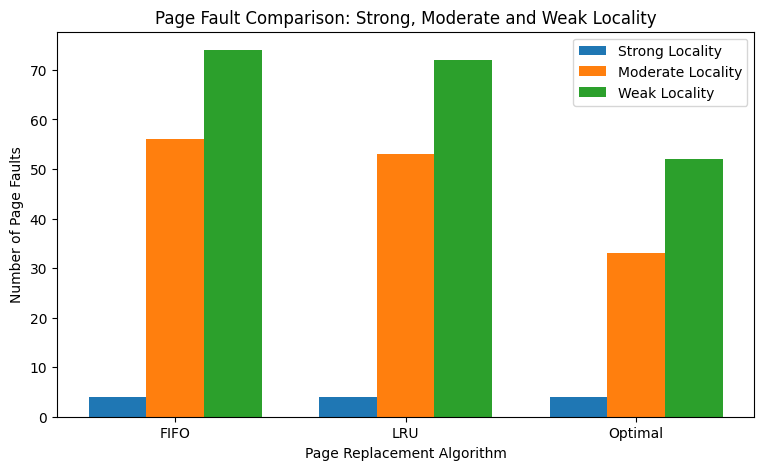

In [23]:
algorithms = ["FIFO", "LRU", "Optimal"]

strong_faults = [
    strong_fifo_faults,
    strong_lru_faults,
    strong_optimal_faults
]

moderate_faults = [
    moderate_fifo_faults,
    moderate_lru_faults,
    moderate_optimal_faults
]

weak_faults = [
    weak_fifo_faults,
    weak_lru_faults,
    weak_optimal_faults
]

x = range(len(algorithms))

plt.figure(figsize=(9, 5))

plt.bar(
    [i - 0.25 for i in x],
    strong_faults,
    width=0.25,
    label="Strong Locality"
)

plt.bar(
    x,
    moderate_faults,
    width=0.25,
    label="Moderate Locality"
)

plt.bar(
    [i + 0.25 for i in x],
    weak_faults,
    width=0.25,
    label="Weak Locality"
)

plt.xticks(list(x), algorithms)
plt.xlabel("Page Replacement Algorithm")
plt.ylabel("Number of Page Faults")
plt.title("Page Fault Comparison: Strong, Moderate and Weak Locality")
plt.legend()

plt.show()

In [24]:
strong_rates = [
    strong_fifo_faults / NUM_REFERENCES * 100,
    strong_lru_faults / NUM_REFERENCES * 100,
    strong_optimal_faults / NUM_REFERENCES * 100
]

moderate_rates = [
    moderate_fifo_faults / NUM_REFERENCES * 100,
    moderate_lru_faults / NUM_REFERENCES * 100,
    moderate_optimal_faults / NUM_REFERENCES * 100
]

weak_rates = [
    weak_fifo_faults / NUM_REFERENCES * 100,
    weak_lru_faults / NUM_REFERENCES * 100,
    weak_optimal_faults / NUM_REFERENCES * 100
]

print("Strong Locality:", strong_rates)
print("Moderate Locality:", moderate_rates)
print("Weak Locality:", weak_rates)

Strong Locality: [4.0, 4.0, 4.0]
Moderate Locality: [56.00000000000001, 53.0, 33.0]
Weak Locality: [74.0, 72.0, 52.0]


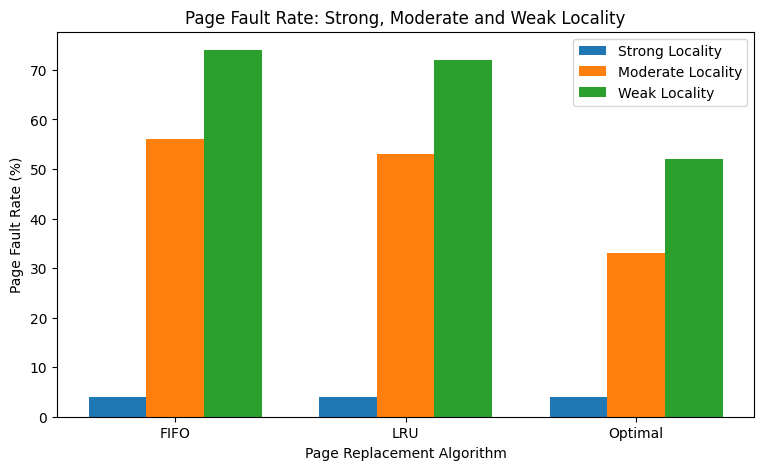

In [25]:
algorithms = ["FIFO", "LRU", "Optimal"]

x = range(len(algorithms))

plt.figure(figsize=(9, 5))

plt.bar(
    [i - 0.25 for i in x],
    strong_rates,
    width=0.25,
    label="Strong Locality"
)

plt.bar(
    x,
    moderate_rates,
    width=0.25,
    label="Moderate Locality"
)

plt.bar(
    [i + 0.25 for i in x],
    weak_rates,
    width=0.25,
    label="Weak Locality"
)

plt.xticks(list(x), algorithms)
plt.xlabel("Page Replacement Algorithm")
plt.ylabel("Page Fault Rate (%)")
plt.title("Page Fault Rate: Strong, Moderate and Weak Locality")
plt.legend()

plt.show()

In [26]:
import pandas as pd

results = pd.DataFrame({
    "Algorithm": ["FIFO", "LRU", "Optimal"],
    "Strong Locality (%)": strong_rates,
    "Moderate Locality (%)": moderate_rates,
    "Weak Locality (%)": weak_rates
})

results

,Algorithm,Strong Locality (%),Moderate Locality (%),Weak Locality (%)
0,FIFO,4.0,56.0,74.0
1,LRU,4.0,53.0,72.0
2,Optimal,4.0,33.0,52.0


In [30]:
# Using standard pandas display to avoid Google Sheets credential authentication errors
display(results)

,Algorithm,Strong Locality (%),Moderate Locality (%),Weak Locality (%)
0,FIFO,4.0,56.0,74.0
1,LRU,4.0,53.0,72.0
2,Optimal,4.0,33.0,52.0


### Final Analysis Summary

Below is the formatted comparison of the page fault rates across different levels of locality:

In [28]:
# Display styled results
styled_results = results.style.format({
    'Strong Locality (%)': '{:.1f}%',
    'Moderate Locality (%)': '{:.1f}%',
    'Weak Locality (%)': '{:.1f}%'
})
display(styled_results)

,Algorithm,Strong Locality (%),Moderate Locality (%),Weak Locality (%)
0,FIFO,4.0%,56.0%,74.0%
1,LRU,4.0%,53.0%,72.0%
2,Optimal,4.0%,33.0%,52.0%


### Final Result Analysis

The experimental results show that locality has a significant effect on page fault rate. Strong locality produces only 4% page faults for all three page replacement algorithms because the same small set of pages is accessed repeatedly.

As locality becomes moderate, the page fault rate increases. FIFO produces 56%, LRU produces 53%, and Optimal produces 33% page faults.

Under weak locality, the page fault rate becomes highest. FIFO produces 74%, LRU produces 72%, while Optimal produces the lowest rate of 52%.

Overall, the results show that better locality reduces page faults and memory pressure. Among the tested algorithms, Optimal gives the lowest page fault rate for moderate and weak locality.

### Real-World Applications

The concept of locality and page replacement is important in modern computer systems.

1. Operating Systems
Page replacement algorithms help operating systems manage limited physical memory efficiently.

2. Web Browsers
Browsers access some pages, images, and data repeatedly. Locality helps improve memory and caching performance.

3. Database Systems
Frequently accessed database records can be kept in faster memory or cache to reduce access time.

4. Cloud Computing
Cloud servers run many applications simultaneously. Efficient memory management helps reduce unnecessary page faults and improve performance.

5. Mobile Devices
Smartphones have limited memory, so efficient memory management helps applications run smoothly.

### Conclusion

This project demonstrates the effect of memory access locality on page faults and the performance of page replacement algorithms. The experimental results show that strong locality produces fewer page faults, while weak locality produces more page faults. Among the tested algorithms, Optimal gives the lowest page fault rate for moderate and weak locality. Therefore, understanding locality is important for efficient memory management and better system performance.

### Future Scope

The project can be extended by adding more page replacement algorithms such as Clock and LFU. It can also be improved by using larger and real-world memory reference traces. A graphical user interface could be developed to allow users to enter their own reference strings and visualize page faults and working-set behavior in real time.

# Virtual Memory Locality Analyzer

## Mini Project on Page Replacement and Memory Locality

**Student Name:** VASALLI SWAPNITH  
**USN:** 25BTRPW100  

### Objective
To analyze how strong, moderate, and weak memory locality affect page faults and to compare FIFO, LRU, and Optimal page replacement algorithms.

In [32]:
## 1. Import Libraries

In [33]:
## 2. Page Replacement Algorithms

In [34]:
## 3. Memory Reference Strings

In [35]:
## 4. Strong and Weak Locality Experiments

In [36]:
## 5. Working-Set Analysis

In [37]:
## 6. Moderate Locality Experiment

In [38]:
## 7. Page Fault Comparison

In [39]:
## 8. Working-Set Size Comparison

In [40]:
## 9. Page Fault Rate Comparison

In [41]:
## 10. Final Results